# LA 03d — Read-only VD18 volatility engine into Liquidity Absorption risk

**Research test, not an investable strategy.** A02 provides signal direction and level; A03/A03c provide first-post-close aggressive or hypothetical passive third-level-revisit entry. **VD18 determines a protective volatility floor on the stop, nominal position budget and horizon diagnostics.** All structural profit targets are held fixed by contract. Run from repo using `deribit-data` kernel.

This uses TRAIN-frozen `VD18 HAR_4` at 15, 60, 240 minutes. It is a forecast of **future terminal SPOT return variance**, not the maximum adverse perp price excursion. The risk transform is exploratory, including transfer from spot to perpetuals. It may still show negative net expectancy. The already-inspected Jul–Sep 2026 period cannot establish new predictive confirmation.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
REPO = Path.cwd().resolve()
while not (REPO / "src" / "data_engineering").is_dir():
    if REPO == REPO.parent:
        raise RuntimeError("Launch notebook from repository tree")
    REPO = REPO.parent
if str(REPO) not in sys.path:
    sys.path.insert(0,str(REPO))
from src.data_engineering.modeling.liquidity_absorption_stage_a import binance_root
from src.data_engineering.modeling.liquidity_absorption_stage_a03d import (
    VERSION, RiskConfig, build_results, spot_history_directory)
assert VERSION == "LA-A03d-0.1.0", "git pull; restart kernel"
DATA_ROOT = binance_root(REPO)
SPOT = spot_history_directory(REPO)
OUT = REPO / "notebooks" / "Liquidity_Absorption" / "03d"
CFG = RiskConfig()
print("Risk bridge:",VERSION,"| Futures:",DATA_ROOT,"| Spot:",SPOT)
print("NO trade directions or structural targets are predicted by VD18")

Risk bridge: LA-A03d-0.1.0 | Futures: D:\MarketData\Binance | Spot: D:\MarketData\Deribit\history\price_5m
NO trade directions or structural targets are predicted by VD18


In [2]:
results = build_results(REPO, DATA_ROOT, SPOT, OUT, CFG)
print("A03d result:", results)
assert results["n_events"]==452


A03d result: {'version': 'LA-A03d-0.1.0', 'status': 'EXPLORATORY_FROZEN_MODEL_RISK_BRIDGE_NO_EDGE_CLAIM', 'n_events': 452, 'n_forecasts': 452, 'n_rows': 4520, 'n_taker_sims': 904, 'n_maker_sims': 1808, 'taker_tape': {'read_daily_parquet_files': 171, 'missing_trade_day_files': ['BTCUSDT:2026-10-01', 'ETHUSDT:2026-10-01']}, 'maker_tape': {'trade_daily_files_read': 170, 'missing_daily_files': ['BTCUSDT:2026-10-01', 'ETHUSDT:2026-10-01']}}


## Model timestamps / causal data coverage

Every signal must use only the **exact most recent completed five-minute spot bar**. No forecast is filled from future bars or from a stale spot return window. Missing history is an explicit no-forecast status. We show the forecast sigma alongside the resulting stop-risk in perp basis points.


In [3]:
events = pd.read_csv(OUT/"03d_event_forecasts.csv")
trades = pd.read_csv(OUT/"03d_risk_execution.csv")
summary = pd.read_csv(OUT/"03d_summary.csv")
paired = pd.read_csv(OUT/"03d_paired_summary.csv")
display(events.groupby(["symbol","forecast_status"]).size().rename("events").reset_index())
display(events.groupby("symbol")[["sigma_bp_15","sigma_bp_60","sigma_bp_240"]].describe().round(3))
print("Coverage, risk-aware costs/returns by policy and holding horizon")
display(summary)
print("240m, paired closed-trade baseline comparison in price basis points")
display(paired)
print("Recorded order outcomes and absence of confirmed fills")
display(trades.groupby(["entry_kind","model_mode","hold_minutes","reason"]).size().rename("n").reset_index())

,symbol,forecast_status,events
0,BTCUSDT,PRESENT,212
1,ETHUSDT,PRESENT,240


sigma_bp_15                                                        \
              count    mean    std    min     25%     50%     75%     max   
symbol                                                                      
BTCUSDT       212.0  16.973  6.783  6.535  12.476  16.247  20.257  54.487   
ETHUSDT       240.0  21.209  7.261  5.965  16.247  20.140  25.621  45.827   

        sigma_bp_60          ...                  sigma_bp_240          \
              count    mean  ...     75%      max        count    mean   
symbol                       ...                                         
BTCUSDT       212.0  35.061  ...  42.156  100.015        212.0  73.276   
ETHUSDT       240.0  44.442  ...  53.687   91.208        240.0  96.376   

                                                           
            std     min     25%     50%      75%      max  
symbol                                                     
BTCUSDT  24.187  30.119  55.533  71.088   87.916  177.929  
ETHUSDT  27.867  29.005  78.803  94.399  113.765  192.308  

[2 rows x 24 columns]

Coverage, risk-aware costs/returns by policy and holding horizon


,entry_kind,model_mode,symbol,hold_minutes,n,n_closed,n_censored,n_entered,mean_net_bp_per_closed,mean_net_r_per_closed,mean_virtual_usdt_per_closed,total_virtual_net_usdt,median_initial_risk_bp,mean_net_bp_per_452_signals_partial
0,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,BTCUSDT,60,212,169,0,169,-8.437220,-0.265678,-5.020699,-848.498164,34.075368,-3.154624
1,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,BTCUSDT,240,212,168,1,169,-9.190877,-0.272725,-5.193409,-872.492792,34.102117,-3.416078
2,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,ETHUSDT,60,240,194,0,194,-10.175530,-0.270984,-5.270272,-1022.432776,41.989698,-4.367373
3,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,ETHUSDT,240,240,194,0,194,-9.774609,-0.239205,-4.746283,-920.778976,41.989698,-4.195297
4,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_TOUCH_3RD,BTCUSDT,60,212,170,0,170,-8.197850,-0.258815,-4.885106,-830.467986,34.102117,-3.083262
5,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_TOUCH_3RD,BTCUSDT,240,212,169,1,170,-8.770879,-0.260605,-4.953984,-837.223363,34.128866,-3.279377
6,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_TOUCH_3RD,ETHUSDT,60,240,194,0,194,-10.377771,-0.275654,-5.366165,-1041.036031,41.989698,-4.454176
7,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_TOUCH_3RD,ETHUSDT,240,240,194,0,194,-9.985112,-0.244312,-4.851076,-941.108654,41.989698,-4.285646
8,TAKER_FIRST_POST_SIGNAL,VD18_VOL_BREAKEVEN,BTCUSDT,60,212,196,0,196,-11.707308,-0.367975,-6.174449,-1210.192072,33.646954,-5.076620
9,TAKER_FIRST_POST_SIGNAL,VD18_VOL_BREAKEVEN,BTCUSDT,240,212,195,1,196,-14.041097,-0.412657,-7.030943,-1371.033878,33.924296,-6.057553


240m, paired closed-trade baseline comparison in price basis points


,symbol,baseline,paired_closed,mean_original_net_bp,mean_vol_net_bp,mean_vol_minus_original_bp
0,BTCUSDT,A03C_MAKER_TOUCH,169,-10.601570,-8.770879,1.830691
1,BTCUSDT,A03_ORIGINAL_TAKER_FIXED,195,-13.599220,-13.807337,-0.208117
2,ETHUSDT,A03C_MAKER_TOUCH,193,-9.226647,-9.786948,-0.560302
3,ETHUSDT,A03_ORIGINAL_TAKER_FIXED,219,-13.645988,-12.638691,1.007297


Recorded order outcomes and absence of confirmed fills


,entry_kind,model_mode,hold_minutes,reason,n
0,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,60,NO_STRUCTURAL_TARGET,37
1,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,60,NO_THIRD_TOUCH,24
2,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,60,NO_TRADE_THROUGH,1
3,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,60,STOP,118
4,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,60,TARGET,47
5,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,60,TARGET_REACHED_BEFORE_MAKER_FILL,27
6,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,60,TIMEOUT,198
7,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,240,CENSORED_TAPE_GAP,1
8,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,240,NO_STRUCTURAL_TARGET,37
9,MAKER_ELIGIBILITY_ONLY,VD18_VOL_MAKER_THROUGH_3RD,240,NO_THIRD_TOUCH,24


## Virtual equity and stop-distance plots

The virtual P&L curve applies a constant **hypothetical risk budget** per trade, capped by reference notional. Trades can overlap; this is **not an account equity curve**. Maker-eligibility scenarios are not known maker fills and remain conditional on unavailable quote/queue state.


03d_virtual_equity.png


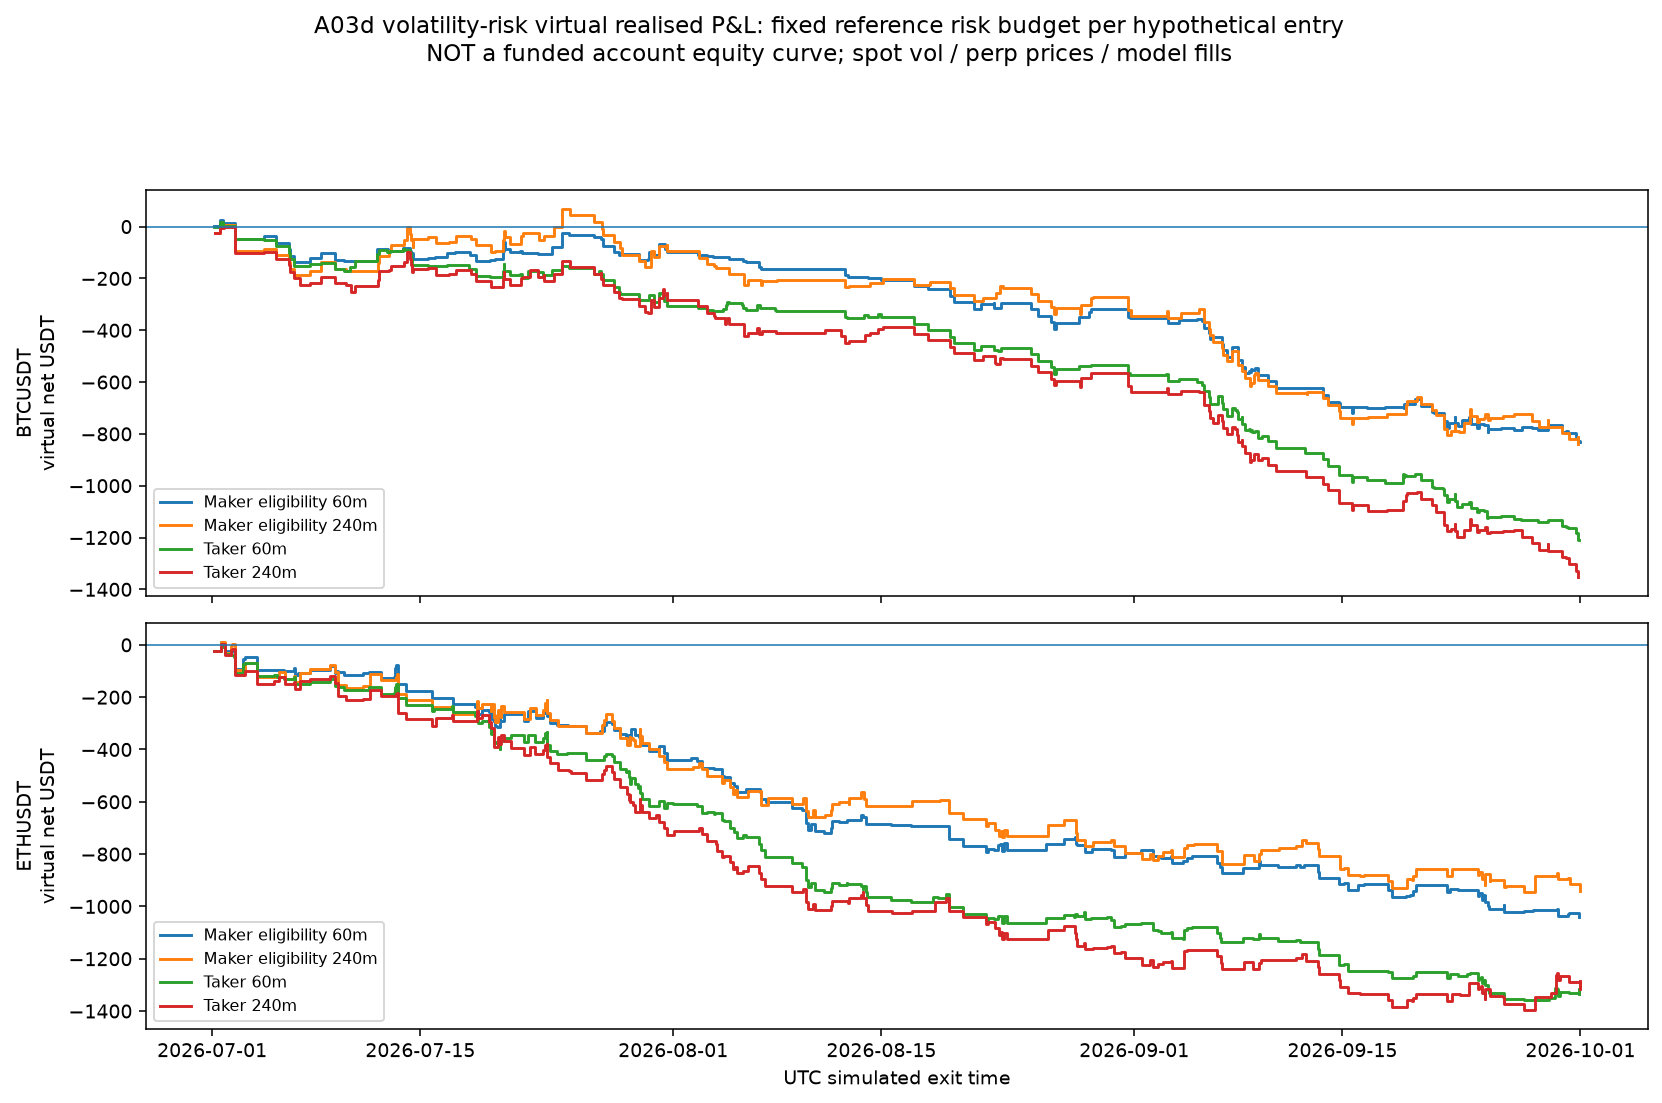

03d_forecast_vs_stop.png


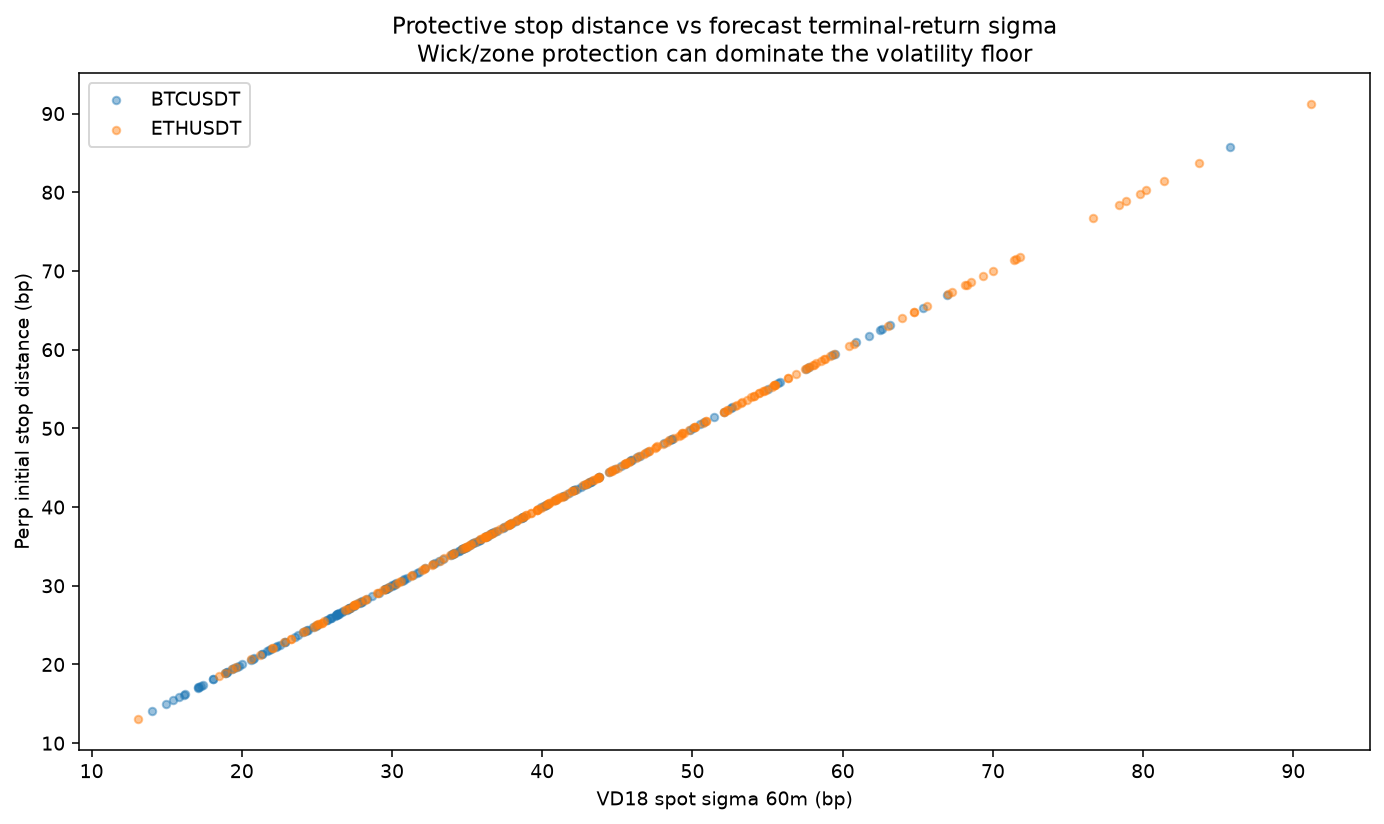

In [4]:
for name in ("03d_virtual_equity.png","03d_forecast_vs_stop.png"):
    pic=OUT/name
    if pic.exists():
        print(name)
        display(Image(filename=str(pic)))

## Decision gate

1. This module deliberately does **not** optimize sigma multipliers or 60/240-minute holding limits using already-inspected July–September outcomes.
2. Forecast sigma is a terminal-variance measure; wick protection and liquidity invalidation must remain, since sigma alone does not imply stop-first probability.
3. The source spot price window is independent of perp execution, so spot/perpetual variance transfer remains an empirical question.
4. Stop sizing, fee allowance, virtual dollar risk and maker fill proxies are **not proof of live profitability**, portfolio capital adequacy, fill probability or actual funding-adjusted returns.
5. Earlier A03, A03b, A03c and Volatility Dynamics outputs are left untouched. Push executed notebook and `03d/` CSV/JSON/PNG artifacts for review.
